# Public data experiments
This is the notebook to run the public data experiment

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

# Add the workspace root to sys.path
workspace_root = Path("/Users/eduardohome/workspace/benchmark_credit_scoring")
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))

# Now you can import from src
from src.utils.csv_config import read_csv_by_name, create_imbalanced_datasets, merge_xai_results
from src.model.functions import save_model, load_model, get_split_data
from src.xai.functions import get_train_iterations_shap, compute_xai_metrics_from_shap
from src.graph.functions import plot_model_boxplot, plot_imbalance_boxplot_grid, load_xai_file, plot_models_by_imbalance

try:
    from src.model.functions import get_train_model
except Exception as exc:
    # provide helpful message if import fails
    print("Failed to import model utilities:", exc)
    print("This often means a missing dependency such as libomp for LightGBM.")
    print("On macOS you can install it with `brew install libomp` and then restart the kernel.")
    raise

# General imports
import pandas as pd
from pathlib import Path

In [2]:
# -------------------------
# Settings
# -------------------------
data_dir = Path("/Users/eduardohome/workspace/benchmark_credit_scoring/data")
#datasets_to_run = ["australian", "german", "japan", "kgccdea", "taiwan", "th02"] #kggmsc #taiwan
datasets_to_run = ["australian", "german", "japan", "kgccdea", "th02"] #kggmsc #taiwan
#datasets_to_run = ["australian"]
target_col = "target"

# Edit this list whenever you want more/less imbalance datasets
imbalance_levels = [10, 15, 20, 25]
#imbalance_levels = [1, 2.5, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
n_iterations = 100
percentage = 90

# list of estimators understood by functions.get_model
model_choices = ["LightGBM", "XGBoost", "RandomForest", "BoostDT", "BoostSGB", "BagNN", "ANN"] #, "SVM-Rbf"
#model_choices = ["XGBoost"] #, "SVM-Rbf"
product = "default"

In [3]:
import numpy as np
import pandas as pd


def generate_boxplot_data(
    model_names=None,
    n_obs=100,
    means=None,
    stds=None,
    random_state=42,
    outlier_fraction=0.02,
    outlier_scale=3.0,
):
    """
    Generate random boxplot data with per-model outlier control.

    outlier_fraction:
        float OR list of floats

    outlier_scale:
        float OR list of floats
    """

    if model_names is None:
        model_names = ["Model_1", "Model_2", "Model_3"]

    n_models = len(model_names)

    if means is None:
        means = np.linspace(0.03, 0.12, n_models)

    if stds is None:
        stds = np.repeat(0.015, n_models)

    # Convert scalar to list
    if isinstance(outlier_fraction, (int, float)):
        outlier_fraction = [outlier_fraction] * n_models

    if isinstance(outlier_scale, (int, float)):
        outlier_scale = [outlier_scale] * n_models

    rng = np.random.default_rng(random_state)
    data = {}

    for name, mean, std, frac, scale in zip(
        model_names, means, stds, outlier_fraction, outlier_scale
    ):
        values = rng.normal(mean, std, n_obs)

        n_out = int(n_obs * frac)

        if n_out > 0:
            idx = rng.choice(n_obs, size=n_out, replace=False)

            values[idx] = rng.normal(
                loc=mean + scale * std,
                scale=std,
                size=n_out
            )

        data[name] = np.clip(values, 0, None)

    return pd.DataFrame(data)

In [4]:
def plot_model_boxplots(
    df,
    title="Benchmark Stability Comparison",
    ylabel="Local Stability",
    figsize=(10, 5),
    rotate_labels=0,
    y_bottom=0,
    y_top=0.30,
    show_quartile_lines=True,
):
    model_names = df.columns.tolist()

    x_labels = []
    quartiles = {}

    for col in model_names:
        vals = df[col].dropna()
        q1 = np.percentile(vals, 25)
        q2 = np.percentile(vals, 50)
        q3 = np.percentile(vals, 75)
        iqr = q3 - q1

        quartiles[col] = {"q1": q1, "q2": q2}
        x_labels.append(f"{col}\nMd={q2:.3f}\nIQR={iqr:.3f}")

    fig, ax = plt.subplots(figsize=figsize)

    bp = ax.boxplot(
        [df[col].dropna() for col in model_names],
        patch_artist=True,
        showfliers=True,
        medianprops=dict(color="black", linewidth=1.2),
        boxprops=dict(linewidth=1.0),
        whiskerprops=dict(linewidth=1.0),
        capprops=dict(linewidth=1.0),
        flierprops=dict(marker="o", markersize=3, alpha=0.7),
    )

    gray_values = np.linspace(0.85, 0.25, len(model_names))
    for patch, gray in zip(bp["boxes"], gray_values):
        patch.set_facecolor(str(gray))

    ax.set_xticks(range(1, len(model_names) + 1))
    ax.set_xticklabels(x_labels)

    ax.set_title(title, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_ylim(y_bottom, y_top)

    ax.grid(axis="y", linestyle="-", alpha=0.20)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(axis="x", labelsize=7, rotation=rotate_labels, pad=4)
    ax.tick_params(axis="y", labelsize=8)

    if show_quartile_lines:
        for i, col in enumerate(model_names, start=1):
            q1 = quartiles[col]["q1"]
            q2 = quartiles[col]["q2"]

            ax.text(i + 0.12, q1, f"Q1={q1:.3f}", fontsize=6, va="center")
            ax.text(i + 0.12, q2, f"Q2={q2:.3f}", fontsize=6, va="center")

    fig.tight_layout()

    return fig, ax

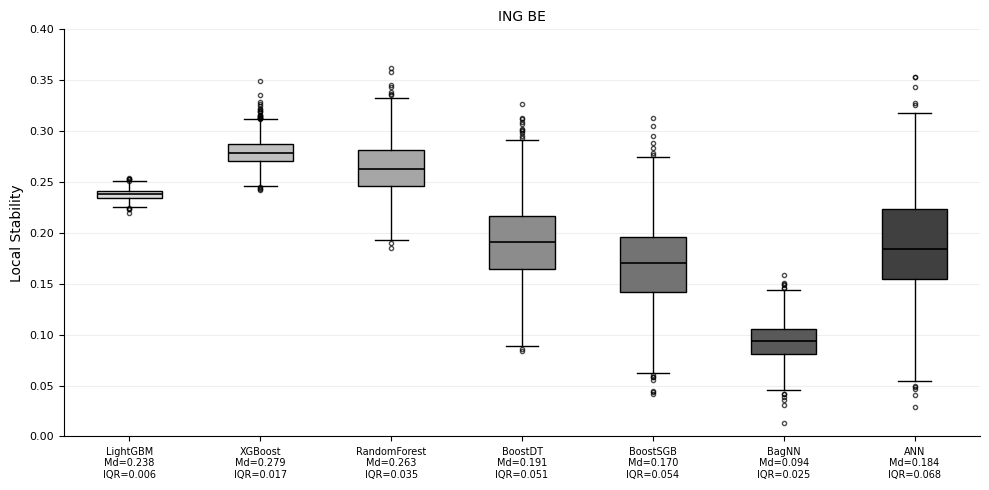

In [5]:
means = [0.238, 0.279, 0.262, 0.191, 0.171, 0.092, 0.185]
stds  = [0.005, 0.012, 0.025, 0.039, 0.041, 0.018, 0.051]

outlier_fraction = [0.01, 0.03, 0.01, 0.01, 0.02, 0.02, 0.01]
outlier_scale    = [1.5, 3.0, 2.0, 2.0, 1.0, 2.0, 2.0]

df_random = generate_boxplot_data(
    model_names=model_choices,
    n_obs=1000,
    means=means,
    stds=stds,
    outlier_fraction=outlier_fraction,
    outlier_scale=outlier_scale,
    random_state=42
)

fig, ax = plot_model_boxplots(
    df_random,
    title="ING BE",
    ylabel="Local Stability",
    y_bottom=0,
    y_top=0.40,
    show_quartile_lines=False,
)

fig.savefig(
    "figure_2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
import pandas as pd

# =====================================================
# CREATE LATEX TABLE FROM BOXPLOT PARAMETERS
# No jinja2 required
# =====================================================

def create_latex_table_from_boxplot_params(
    model_names,
    means,
    stds,
    outlier_fraction=None,
    outlier_scale=None,
    model_name_map=None,
    model_order=None,
    caption="Simulation parameters used to generate the boxplots",
    label="tab:boxplot_simulation_params",
    save_path=None,
):
    df_latex = pd.DataFrame({
        "Model": model_names,
        "Mean": means,
        "Std": stds,
    })

    if outlier_fraction is not None:
        df_latex["Outlier fraction"] = outlier_fraction

    if outlier_scale is not None:
        df_latex["Outlier scale"] = outlier_scale

    if model_order is not None:
        df_latex["Model"] = pd.Categorical(
            df_latex["Model"],
            categories=model_order,
            ordered=True,
        )
        df_latex = df_latex.sort_values("Model")

    df_latex["Model"] = df_latex["Model"].astype(str)

    if model_name_map is not None:
        df_latex["Model"] = df_latex["Model"].replace(model_name_map)

    numeric_cols = df_latex.select_dtypes(include="number").columns
    df_latex[numeric_cols] = df_latex[numeric_cols].round(3)

    cols = df_latex.columns.tolist()

    header = " & ".join([f"\\textbf{{{col}}}" for col in cols]) + r" \\"

    latex_rows = []

    for _, row in df_latex.iterrows():
        values = []

        for col in cols:
            value = row[col]

            if isinstance(value, float):
                values.append(f"{value:.3f}")
            else:
                values.append(str(value))

        latex_rows.append(" & ".join(values) + r" \\")

    latex_table = r"""
\begin{table}[!ht]
\centering
\caption{""" + caption + r"""}
\label{""" + label + r"""}
\begin{tabular}{l""" + "c" * (len(cols) - 1) + r"""}
\toprule
""" + header + r"""
\midrule
""" + "\n".join(latex_rows) + r"""
\bottomrule
\end{tabular}
\end{table}
"""

    if save_path is not None:
        with open(save_path, "w") as f:
            f.write(latex_table)

        print("[OK] LaTeX table saved to:", save_path)

    return df_latex, latex_table


# =====================================================
# EXAMPLE USAGE
# =====================================================

means = [0.238, 0.279, 0.262, 0.191, 0.171, 0.092, 0.185]
stds  = [0.005, 0.012, 0.025, 0.039, 0.041, 0.018, 0.051]

outlier_fraction = [0.01, 0.03, 0.01, 0.01, 0.02, 0.02, 0.01]
outlier_scale    = [1.5, 3.0, 2.0, 2.0, 1.0, 2.0, 2.0]

model_name_map = {
    "RandomForest": "RF",
    "XGBoost": "XGB",
    "LightGBM": "LGBM",
    "BagNN": "BagNN",
    "ANN": "ANN",
    "BoostDT": "BoostDT",
    "BoostSGB": "BoostSGB",
}

model_order = [
    "RandomForest",
    "XGBoost",
    "LightGBM",
    "BoostSGB",
    "BoostDT",
    "ANN",
    "BagNN",
]

df_params, latex_table = create_latex_table_from_boxplot_params(
    model_names=model_choices,
    means=means,
    stds=stds,
    outlier_fraction=outlier_fraction,
    outlier_scale=outlier_scale,
    model_name_map=model_name_map,
    model_order=model_order,
    caption="Simulation parameters used to generate the local stability boxplots",
    label="tab:local_stability_simulation_params",
    save_path=data_dir / "local_stability_simulation_params.tex",
)

display(df_params)

print(latex_table)

[OK] LaTeX table saved to: /Users/eduardohome/workspace/benchmark_credit_scoring/data/local_stability_simulation_params.tex


,Model,Mean,Std,Outlier fraction,Outlier scale
2,RF,0.262,0.025,0.01,2.0
1,XGB,0.279,0.012,0.03,3.0
0,LGBM,0.238,0.005,0.01,1.5
4,BoostSGB,0.171,0.041,0.02,1.0
3,BoostDT,0.191,0.039,0.01,2.0
6,ANN,0.185,0.051,0.01,2.0
5,BagNN,0.092,0.018,0.02,2.0



\begin{table}[!ht]
\centering
\caption{Simulation parameters used to generate the local stability boxplots}
\label{tab:local_stability_simulation_params}
\begin{tabular}{lcccc}
\toprule
\textbf{Model} & \textbf{Mean} & \textbf{Std} & \textbf{Outlier fraction} & \textbf{Outlier scale} \\
\midrule
RF & 0.262 & 0.025 & 0.010 & 2.000 \\
XGB & 0.279 & 0.012 & 0.030 & 3.000 \\
LGBM & 0.238 & 0.005 & 0.010 & 1.500 \\
BoostSGB & 0.171 & 0.041 & 0.020 & 1.000 \\
BoostDT & 0.191 & 0.039 & 0.010 & 2.000 \\
ANN & 0.185 & 0.051 & 0.010 & 2.000 \\
BagNN & 0.092 & 0.018 & 0.020 & 2.000 \\
\bottomrule
\end{tabular}
\end{table}



In [ ]:
import pandas as pd

# =====================================================
# INPUTS YOU CAN MODIFY
# =====================================================

model_order = [
    "RandomForest",
    "XGBoost",
    "LightGBM",
    "BoostSGB",
    "BoostDT",
    "ANN",
    "BagNN",
]

model_name_map = {
    "RandomForest": "RF",
    "XGBoost": "XGB",
    "LightGBM": "LGBM",
    "BoostSGB": "BoostSGB",
    "BoostDT": "BoostDT",
    "ANN": "ANN",
    "BagNN": "BagNN",
}

# Manual ranks you want to control
manual_values = {
    "RandomForest": {"AUC": 2.7, "PG": 2.7, "K-S": 3.2, "SRA": 2.3, "CV": 2.4},
    "XGBoost":     {"AUC": 2.9, "PG": 3.0, "K-S": 3.9, "SRA": 2.5, "CV": 3.3},
    "LightGBM":    {"AUC": 3.0, "PG": 2.8, "K-S": 3.6, "SRA": 2.2, "CV": 3.4},
    "BoostSGB":    {"AUC": 3.4, "PG": 3.4, "K-S": 3.4, "SRA": 4.9, "CV": 4.4},
    "BoostDT":     {"AUC": 2.6, "PG": 3.5, "K-S": 3.0, "SRA": 4.4, "CV": 4.7},
    "ANN":         {"AUC": 5.4, "PG": 4.9, "K-S": 4.6, "SRA": 2.0, "CV": 4.4},
    "BagNN":       {"AUC": 5.8, "PG": 5.3, "K-S": 5.4, "SRA": 3.6, "CV": 5.0},
}

# Parameters used to automatically compute SMLI rank
smli_values = {
    "RandomForest": 0.238,
    "XGBoost": 0.279,
    "LightGBM": 0.262,
    "BoostSGB": 0.191,
    "BoostDT": 0.171,
    "ANN": 0.092,
    "BagNN": 0.185,
}

# For SMLI: higher stability is better, so highest value gets rank 1
smli_higher_is_better = True


# =====================================================
# BUILD TABLE DATAFRAME
# =====================================================

df_table = pd.DataFrame.from_dict(manual_values, orient="index")
df_table.index.name = "Model"
df_table = df_table.reset_index()

df_smli = pd.DataFrame({
    "Model": list(smli_values.keys()),
    "SMLI_value": list(smli_values.values()),
})

df_smli["SMLI"] = df_smli["SMLI_value"].rank(
    method="dense",
    ascending=not smli_higher_is_better,
)

df_table = df_table.merge(
    df_smli[["Model", "SMLI"]],
    on="Model",
    how="left",
)

df_table = df_table[["Model", "AUC", "PG", "K-S", "SMLI", "SRA", "CV"]]

df_table["Model"] = pd.Categorical(
    df_table["Model"],
    categories=model_order,
    ordered=True,
)

df_table = df_table.sort_values("Model")
df_table["Model"] = df_table["Model"].astype(str).replace(model_name_map)

for col in ["AUC", "PG", "K-S", "SMLI", "SRA", "CV"]:
    df_table[col] = df_table[col].astype(float).round(1)


# =====================================================
# GENERATE EXACT LATEX TABLE STRUCTURE
# =====================================================

latex_rows = []

for _, row in df_table.iterrows():
    latex_rows.append(
        f"{row['Model']:<8} & "
        f"{row['AUC']:.1f} & "
        f"{row['PG']:.1f} & "
        f"{row['K-S']:.1f} & "
        f"{row['SMLI']:.1f} & "
        f"{row['SRA']:.1f} & "
        f"{row['CV']:.1f} \\\\"
    )

latex_table = r"""
\begin{table}[!ht]
\centering
\caption{Performance and Stability Measures for the Real-World Dataset}
\label{tab:ResultsRealTable}

\begin{adjustbox}{max width=\columnwidth}
\begin{tabular}{lcccccc}
\toprule
& \multicolumn{3}{c}{\textbf{Traditional Performance Metrics}}
& \multicolumn{3}{c}{\textbf{Stability Measures}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7}
\textbf{Model} & \textbf{AUC} & \textbf{PG} & \textbf{K-S}
& \textbf{SMLI} & \textbf{SRA} & \textbf{CV} \\
\midrule
""" + "\n".join(latex_rows) + r"""
\bottomrule
\end{tabular}
\end{adjustbox}
\end{table}
"""

print(latex_table)
display(df_table)

# Optional save
with open(data_dir / "latex_table_real_dataset.tex", "w") as f:
    f.write(latex_table)


\begin{table}[!ht]
\centering
\caption{Performance Metrics and Stability Measures for Different Models}
\label{tab:ResultsBenchTable}

\begin{adjustbox}{max width=\columnwidth}
\begin{tabular}{lcccccc}
\toprule
& \multicolumn{3}{c}{\textbf{Traditional Performance Metrics}}
& \multicolumn{3}{c}{\textbf{Stability Measures}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7}
\textbf{Model} & \textbf{AUC} & \textbf{PG} & \textbf{K-S}
& \textbf{SMLI} & \textbf{SRA} & \textbf{CV} \\
\midrule
RF       & 2.7 & 2.7 & 3.2 & 3.0 & 2.3 & 2.4 \\
XGB      & 2.9 & 3.0 & 3.9 & 1.0 & 2.5 & 3.3 \\
LGBM     & 3.0 & 2.8 & 3.6 & 2.0 & 2.2 & 3.4 \\
BoostSGB & 3.4 & 3.4 & 3.4 & 4.0 & 4.9 & 4.4 \\
BoostDT  & 2.6 & 3.5 & 3.0 & 6.0 & 4.4 & 4.7 \\
ANN      & 5.4 & 4.9 & 4.6 & 7.0 & 2.0 & 4.4 \\
BagNN    & 5.8 & 5.3 & 5.4 & 5.0 & 3.6 & 5.0 \\
\bottomrule
\end{tabular}
\end{adjustbox}
\end{table}



,Model,AUC,PG,K-S,SMLI,SRA,CV
0,RF,2.7,2.7,3.2,3.0,2.3,2.4
1,XGB,2.9,3.0,3.9,1.0,2.5,3.3
2,LGBM,3.0,2.8,3.6,2.0,2.2,3.4
3,BoostSGB,3.4,3.4,3.4,4.0,4.9,4.4
4,BoostDT,2.6,3.5,3.0,6.0,4.4,4.7
5,ANN,5.4,4.9,4.6,7.0,2.0,4.4
6,BagNN,5.8,5.3,5.4,5.0,3.6,5.0
